**Célula 1 – setup e dados:**

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

both = pd.read_csv("results/tables/12_classification_vs_retrieval.csv")   
ret = pd.read_csv("results/tables/12_retrieval_precision.csv")           
clf = pd.read_csv("results/tables/09_classification_table.csv")          
print(both.round(4).to_string(index=False))

     space  test_acc   p@10  rank_classification  rank_retrieval
    AE-128    0.8576 0.8243                    1               1
       HOG    0.8444 0.7821                    2              10
     AE-64    0.8434 0.8214                    3               2
   PCA-128    0.8414 0.8064                    4               5
raw pixels    0.8329 0.8004                    5               8
    PCA-64    0.8324 0.8033                    6               6
     AE-32    0.8234 0.8177                    7               3
    PCA-32    0.8154 0.7965                    8               9
     AE-16    0.8012 0.8121                    9               4
    PCA-16    0.7870 0.7777                   10              11
      AE-8    0.7664 0.8008                   11               7
     PCA-8    0.7302 0.7277                   12              12
      AE-2    0.6166 0.6708                   13              13
     PCA-2    0.5093 0.4507                   14              14


**Célula 2 – figura-resumo: accuracy vs precision@10:**

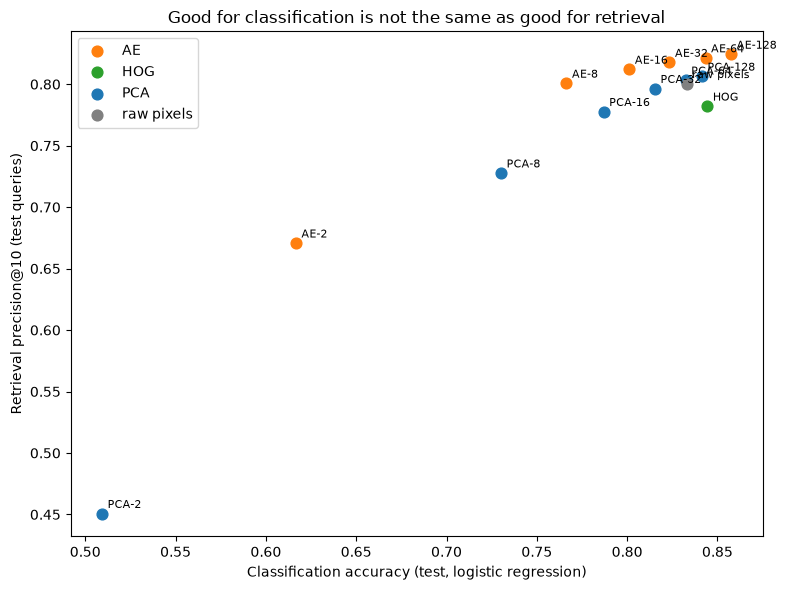

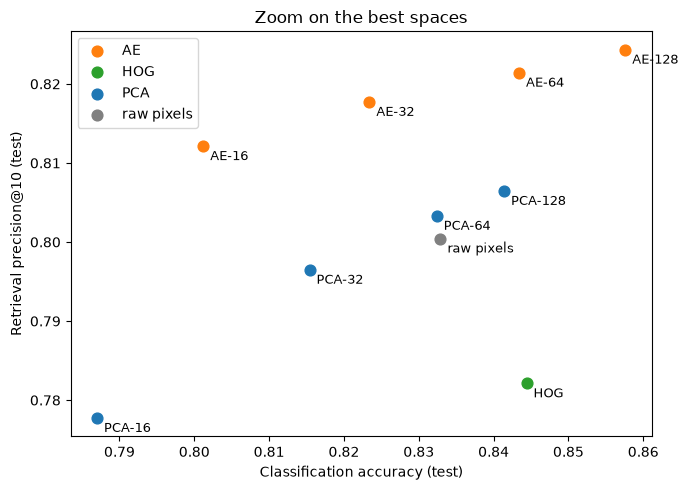

In [5]:
def family(name):
    """Agrupa os espaços em famílias, para pintar o gráfico."""
    for f in ["PCA", "AE"]:
        if name.startswith(f):
            return f
    return name                                            


both["family"] = both["space"].apply(family)
colors = {"PCA": "tab:blue", "AE": "tab:orange", "raw pixels": "gray", "HOG": "tab:green"}

fig, ax = plt.subplots(figsize=(8, 6))
for fam, sub in both.groupby("family"):
    ax.scatter(sub["test_acc"], sub["p@10"], s=60, color=colors[fam], label=fam)
for _, r in both.iterrows():
    ax.annotate(r["space"], (r["test_acc"], r["p@10"]), fontsize=8,
                xytext=(4, 4), textcoords="offset points")         
ax.set_xlabel("Classification accuracy (test, logistic regression)")
ax.set_ylabel("Retrieval precision@10 (test queries)")
ax.set_title("Good for classification is not the same as good for retrieval")
ax.legend()
plt.tight_layout()
plt.savefig("results/figures/16_classification_vs_retrieval.png", dpi=150, bbox_inches="tight")
plt.show()


fig, ax = plt.subplots(figsize=(7, 5))
zoom = both[both["test_acc"] > 0.78]                                    
for fam, sub in zoom.groupby("family"):
    ax.scatter(sub["test_acc"], sub["p@10"], s=60, color=colors[fam], label=fam)
for _, r in zoom.iterrows():
    ax.annotate(r["space"], (r["test_acc"], r["p@10"]), fontsize=9, xytext=(5, -10), textcoords="offset points")
ax.set_xlabel("Classification accuracy (test)")
ax.set_ylabel("Retrieval precision@10 (test)")
ax.set_title("Zoom on the best spaces")
ax.legend()
plt.tight_layout()
plt.savefig("results/figures/16_classification_vs_retrieval_zoom.png", dpi=150, bbox_inches="tight")
plt.show()

**Célula 3 – com quantas dimensões “satura” cada tarefa:**

In [3]:
def saturation_dim(df, metric, tol=0.01):
    """Menor dimensão cujo valor está a menos de 'tol' (1 ponto percentual) do melhor dessa família."""
    best = df[metric].max()
    return int(df[df[metric] >= best - tol]["dim"].min())


rows = []
for fam in ["PCA", "AE"]:
    c = clf[clf.space == fam]
    r = ret[ret.family == fam]
    rows.append({"family": fam,
                 "best accuracy": c["test_acc"].max(),
                 "saturation dim (classification)": saturation_dim(c, "test_acc"),
                 "best p@10": r["p@10"].max(),
                 "saturation dim (retrieval)": saturation_dim(r, "p@10")})
sat = pd.DataFrame(rows)
print(sat.round(4).to_string(index=False))
sat.to_csv("results/tables/16_saturation.csv", index=False)

family  best accuracy  saturation dim (classification)  best p@10  saturation dim (retrieval)
   PCA         0.8414                               64     0.8064                          32
    AE         0.8576                              128     0.8243                          32


**Célula 4 – as duas tarefas ordenam os espaços da mesma forma?**

In [4]:
rho_all = both["test_acc"].corr(both["p@10"], method="spearman")
rho_no_hog = both[both.space != "HOG"]["test_acc"].corr(both[both.space != "HOG"]["p@10"], method="spearman")
print(f"Spearman (todos os espaços): {rho_all:.3f}")
print(f"Spearman (sem o HOG):        {rho_no_hog:.3f}")

both["rank_change"] = both["rank_retrieval"] - both["rank_classification"]
print(both.sort_values("rank_change", key=abs, ascending=False)[
    ["space", "rank_classification", "rank_retrieval", "rank_change"]].head(5).to_string(index=False))

Spearman (todos os espaços): 0.705
Spearman (sem o HOG):        0.835
     space  rank_classification  rank_retrieval  rank_change
       HOG                    2              10            8
     AE-16                    9               4           -5
     AE-32                    7               3           -4
      AE-8                   11               7           -4
raw pixels                    5               8            3
